# Business Problem

Banks give loans to many customers, but not every customer repays properly.
If the bank can predict risky applicants in advance, it can reduce losses.

Goal:

Predict whether a loan applicant is:

Low Risk / Approved-like
High Risk / Default-like

Business value:

Reduces bad loans,
Improves approval decisions,
Helps risk analysis.

#### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier 
from xgboost import XGBClassifier

from sklearn.metrics import(accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve)
import warnings 
warnings.filterwarnings('ignore')

#### Load dataset

In [2]:
df = pd.read_csv("loan_data.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP0,Male,No,2,Graduate,Yes,6019,5419,348,120,0.0,Rural,N
1,LP1,Female,No,0,Not Graduate,Yes,14419,1385,342,120,0.0,Semiurban,N
2,LP2,Male,No,0,Graduate,Yes,2929,2433,272,240,0.0,Semiurban,N
3,LP3,Male,No,3+,Not Graduate,Yes,8264,1301,265,120,0.0,Rural,N
4,LP4,Male,Yes,2,Graduate,Yes,9973,6858,280,180,1.0,Urban,Y


#### Check shape

In [3]:
'Shape of dataset:',df.shape

('Shape of dataset:', (3000, 13))

#### Check columns

In [4]:
'columns:',df.columns.tolist()

('columns:',
 ['Loan_ID',
  'Gender',
  'Married',
  'Dependents',
  'Education',
  'Self_Employed',
  'ApplicantIncome',
  'CoapplicantIncome',
  'LoanAmount',
  'Loan_Amount_Term',
  'Credit_History',
  'Property_Area',
  'Loan_Status'])

#### Check info


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            3000 non-null   object 
 1   Gender             3000 non-null   object 
 2   Married            3000 non-null   object 
 3   Dependents         3000 non-null   object 
 4   Education          3000 non-null   object 
 5   Self_Employed      3000 non-null   object 
 6   ApplicantIncome    3000 non-null   int64  
 7   CoapplicantIncome  3000 non-null   int64  
 8   LoanAmount         3000 non-null   int64  
 9   Loan_Amount_Term   3000 non-null   int64  
 10  Credit_History     3000 non-null   float64
 11  Property_Area      3000 non-null   object 
 12  Loan_Status        3000 non-null   object 
dtypes: float64(1), int64(4), object(8)
memory usage: 304.8+ KB


#### Basic statistics


In [6]:
df.describe(include="all")

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
count,3000,3000,3000,3000,3000,3000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000,3000
unique,3000,2,2,4,2,2,NaN,NaN,NaN,NaN,NaN,3,2
top,LP0,Male,Yes,2,Not Graduate,Yes,NaN,NaN,NaN,NaN,NaN,Rural,N
freq,1,1517,1501,781,1510,1513,NaN,NaN,NaN,NaN,NaN,1051,1774
mean,NaN,NaN,NaN,NaN,NaN,NaN,11066.958667,5072.206667,374.423000,225.120000,0.487667,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,5308.395453,2865.282012,187.506072,88.451079,0.499931,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,2011.000000,0.000000,50.000000,120.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,6400.250000,2614.750000,212.000000,180.000000,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,10985.500000,5161.000000,369.000000,180.000000,0.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,15754.500000,7519.500000,538.000000,240.000000,1.000000,NaN,NaN


#### Check missing values

In [7]:
"Missing values in each column:",df.isnull().sum()

('Missing values in each column:',
 Loan_ID              0
 Gender               0
 Married              0
 Dependents           0
 Education            0
 Self_Employed        0
 ApplicantIncome      0
 CoapplicantIncome    0
 LoanAmount           0
 Loan_Amount_Term     0
 Credit_History       0
 Property_Area        0
 Loan_Status          0
 dtype: int64)

#### Check duplicate rows

In [8]:
"Duplicate rows:", df.duplicated().sum()

('Duplicate rows:', np.int64(0))

#### Remove duplicates

In [9]:
df = df.drop_duplicates()

In [10]:
"Shape after removing duplicates:", df.shape

('Shape after removing duplicates:', (3000, 13))

#### Check target distribution

In [11]:
df["Loan_Status"].value_counts()

Loan_Status
N    1774
Y    1226
Name: count, dtype: int64

#### Visualize target distribution

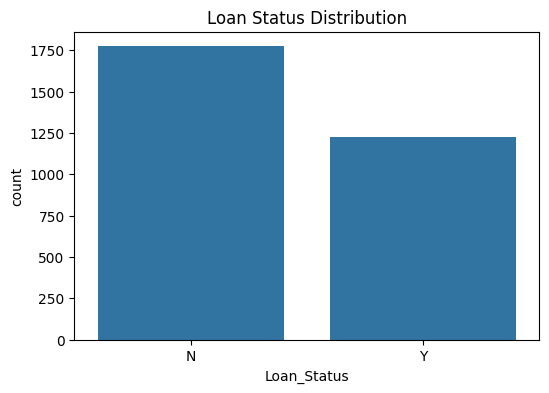

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(x="Loan_Status", data=df)
plt.title("Loan Status Distribution")
plt.show()

# Exploratory Data Analysis

#### Numerical distributions

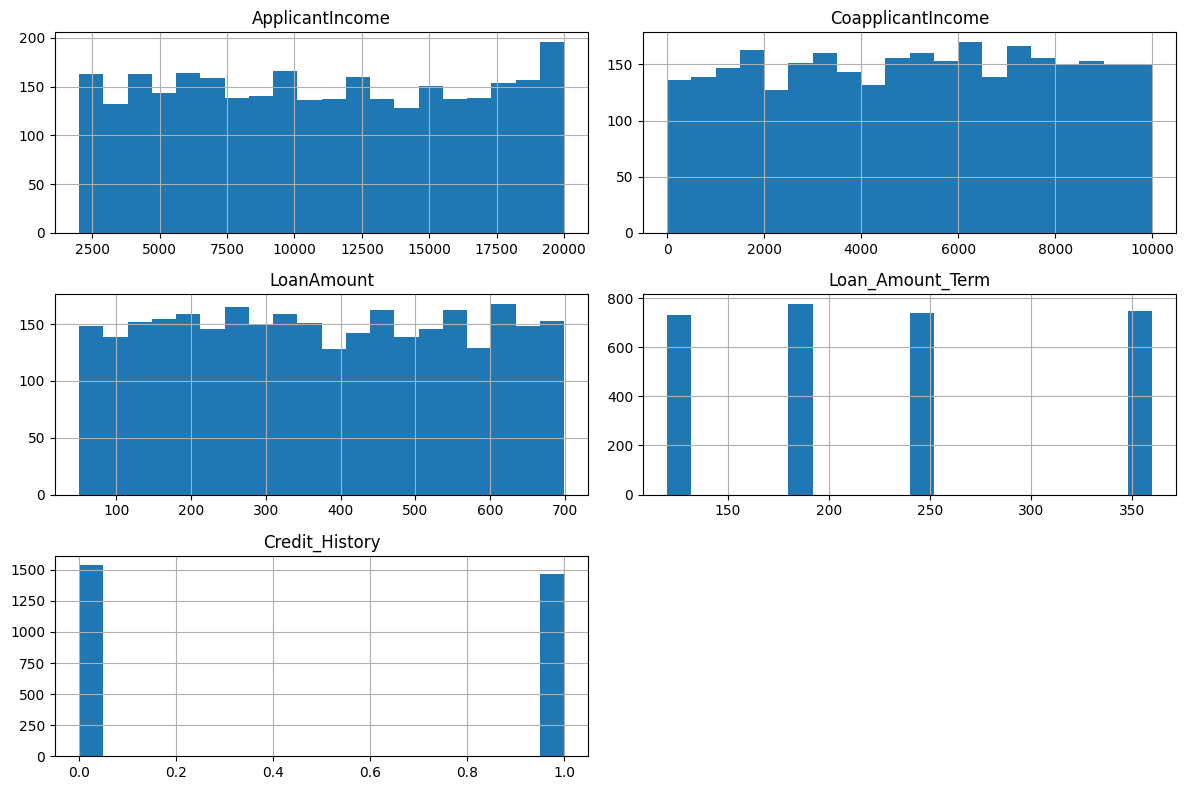

In [13]:
num_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History"]

df[num_cols].hist(figsize=(12,8), bins=20)
plt.tight_layout()
plt.show()

#### Boxplots for outliers

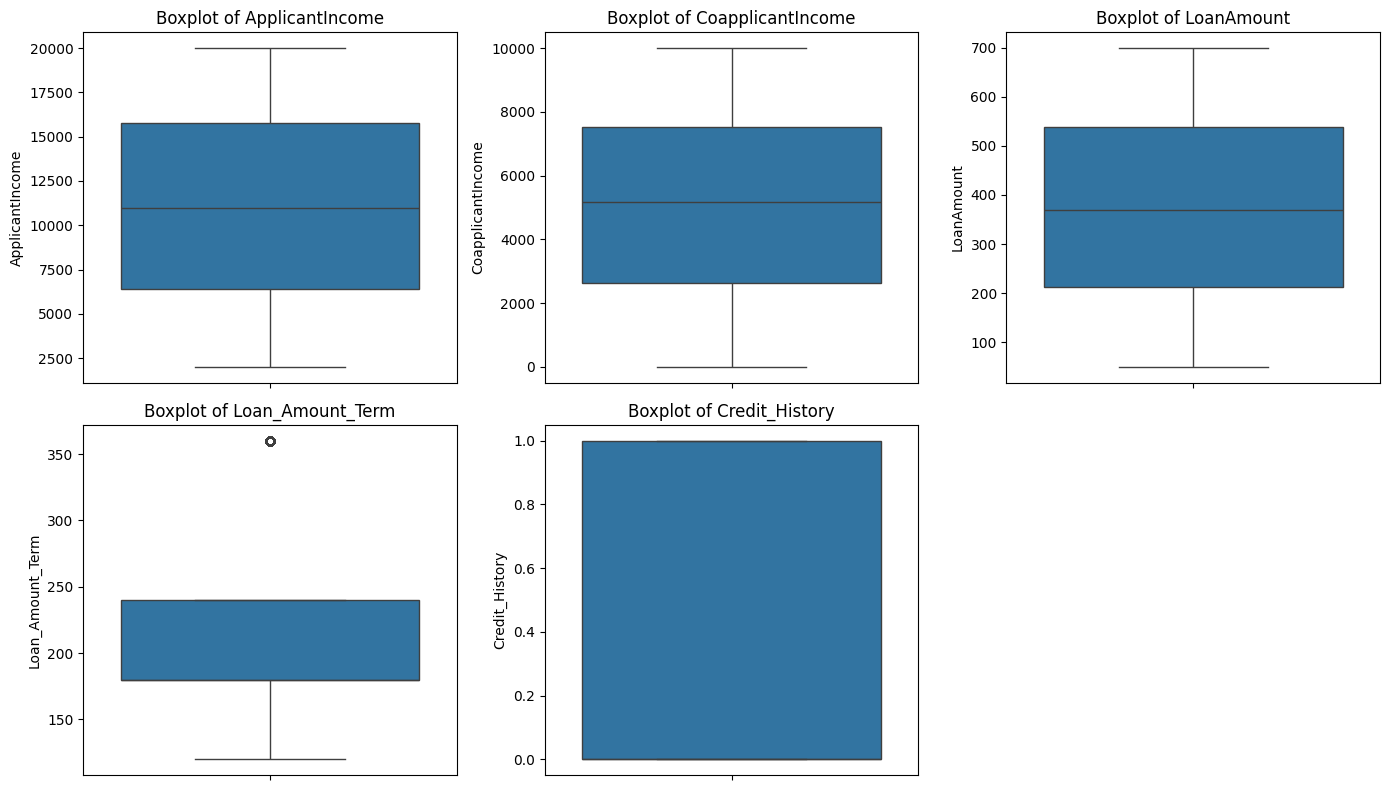

In [14]:
plt.figure(figsize=(14,8))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

#### Categorical vs target

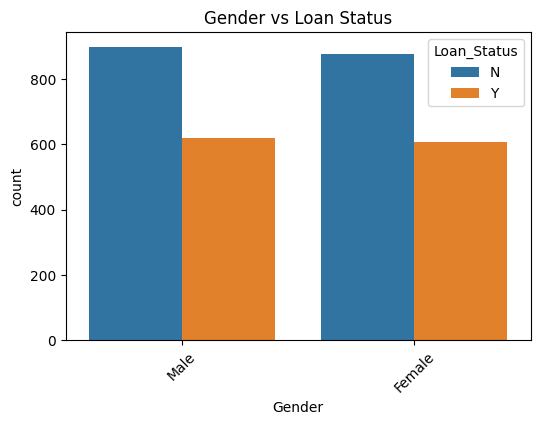

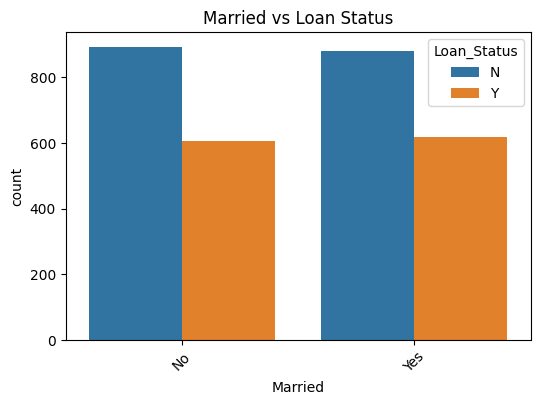

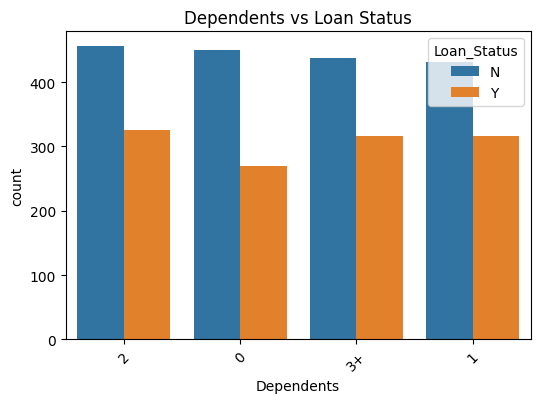

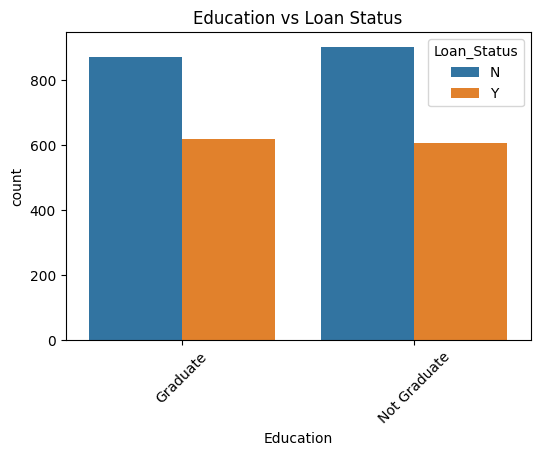

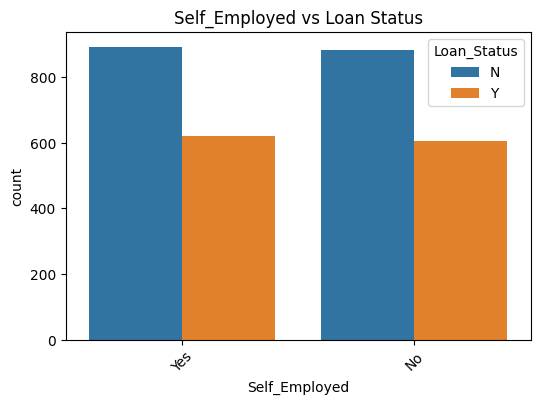

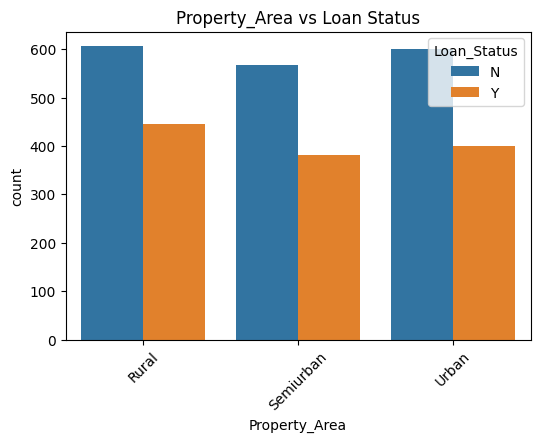

In [15]:
cat_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]

for col in cat_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue="Loan_Status", data=df)
    plt.title(f"{col} vs Loan Status")
    plt.xticks(rotation=45)
    plt.show()

#### Correlation heatmap

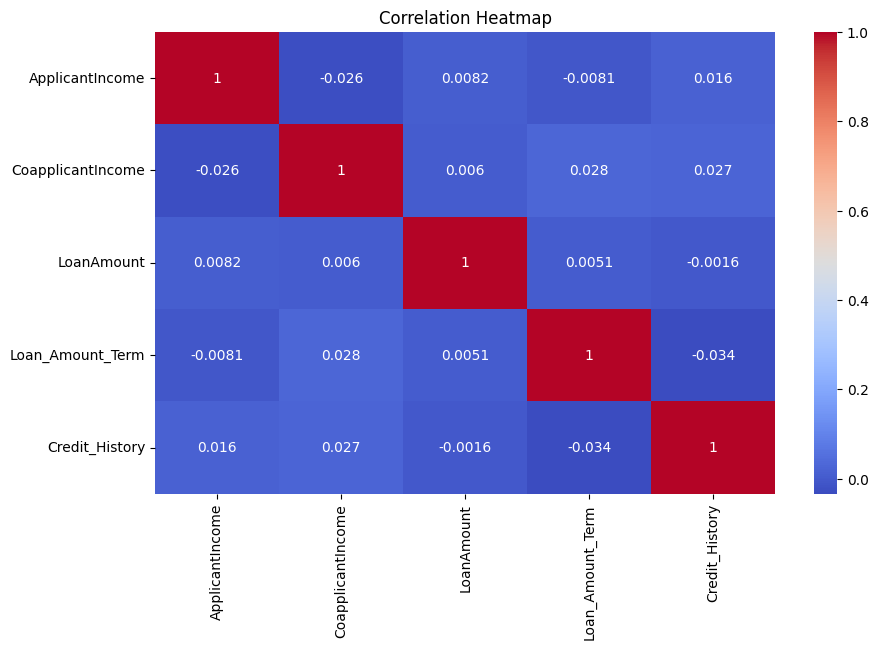

In [16]:
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes(include=["int64", "float64"]).corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Handle Missing Values

#### Impute missing values

In [17]:
df.fillna({
    "Gender": df["Gender"].mode()[0],
    "Married": df["Married"].mode()[0],
    "Dependents": df["Dependents"].mode()[0],
    "Self_Employed": df["Self_Employed"].mode()[0],
    "LoanAmount": df["LoanAmount"].median(),
    "Loan_Amount_Term": df["Loan_Amount_Term"].median(),
    "Credit_History": df["Credit_History"].mode()[0]
}, inplace=True)

print(df.isnull().sum())

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


# Outlier Treatment

#### IQR capping function

In [18]:
def cap_outliers_iqr(dataframe, column):
    Q1 = dataframe[column].quantile(0.25)
    Q3 = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    dataframe[column] = np.where(dataframe[column] < lower, lower, dataframe[column])
    dataframe[column] = np.where(dataframe[column] > upper, upper, dataframe[column])

    return dataframe

#### Apply outlier treatment

In [19]:
outlier_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]

for col in outlier_cols:
    df = cap_outliers_iqr(df, col)

df[outlier_cols].describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount
count,3000.000000,3000.000000,3000.000000
mean,11066.958667,5072.206667,374.423000
std,5308.395453,2865.282012,187.506072
min,2011.000000,0.000000,50.000000
25%,6400.250000,2614.750000,212.000000
50%,10985.500000,5161.000000,369.000000
75%,15754.500000,7519.500000,538.000000
max,19997.000000,9998.000000,699.000000


# Feature Engineering

#### Create new features

In [20]:
df["total_income"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df["income_to_loan_ratio"] = df["total_income"] / (df["LoanAmount"] + 1)
df["log_total_income"] = np.log1p(df["total_income"])
df["log_loan_amount"] = np.log1p(df["LoanAmount"])

df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,total_income,income_to_loan_ratio,log_total_income,log_loan_amount
0,LP0,Male,No,2,Graduate,Yes,6019.0,5419.0,348.0,120,0.0,Rural,N,11438.0,32.773639,9.344784,5.855072
1,LP1,Female,No,0,Not Graduate,Yes,14419.0,1385.0,342.0,120,0.0,Semiurban,N,15804.0,46.075802,9.668082,5.837730
2,LP2,Male,No,0,Graduate,Yes,2929.0,2433.0,272.0,240,0.0,Semiurban,N,5362.0,19.641026,8.587279,5.609472
3,LP3,Male,No,3+,Not Graduate,Yes,8264.0,1301.0,265.0,120,0.0,Rural,N,9565.0,35.958647,9.165970,5.583496
4,LP4,Male,Yes,2,Graduate,Yes,9973.0,6858.0,280.0,180,1.0,Urban,Y,16831.0,59.896797,9.731037,5.638355


#### Check new features visually

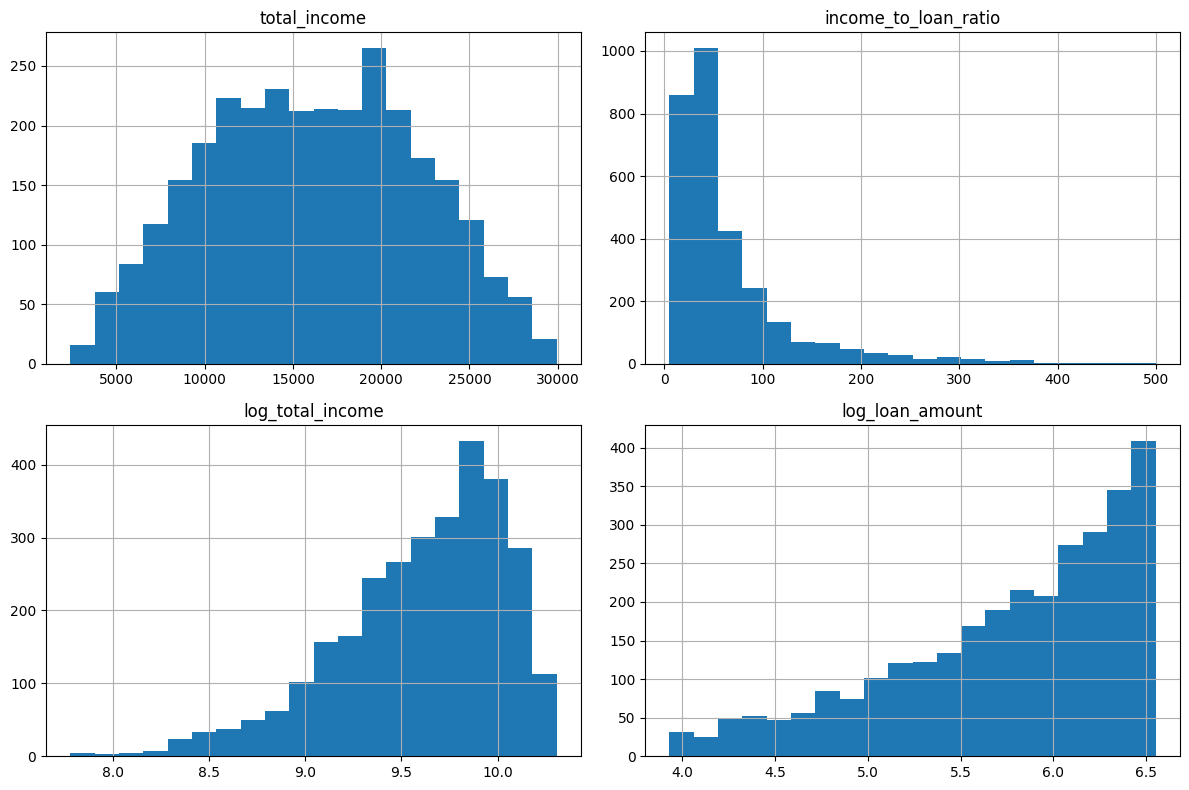

In [21]:
new_num_cols = ["total_income", "income_to_loan_ratio", "log_total_income", "log_loan_amount"]

df[new_num_cols].hist(figsize=(12,8), bins=20)
plt.tight_layout()
plt.show()

# Prepare Data for Modeling

#### Define X and y

In [22]:
X = df.drop(columns=["Loan_ID", "Loan_Status"], errors="ignore")
y = df["Loan_Status"]

#### Encode target

In [23]:
y = y.map({"Y": 0, "N": 1})
print(y.value_counts())

Loan_Status
1    1774
0    1226
Name: count, dtype: int64


#### Separate numeric and categorical columns

In [24]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'total_income', 'income_to_loan_ratio', 'log_total_income', 'log_loan_amount']
Categorical features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


#### Train-test split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(2400, 15) (600, 15)


# Preprocessing Pipeline

#### Create transformers

In [26]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Model 1: Baseline Logistic Regression

#### Train baseline logistic regression

In [27]:
baseline_log_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

baseline_log_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#### Evaluate baseline logistic regression

In [28]:
y_pred_base = baseline_log_model.predict(X_test)
y_prob_base = baseline_log_model.predict_proba(X_test)[:, 1]

print("Baseline Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred_base))
print("Precision:", precision_score(y_test, y_pred_base))
print("Recall:", recall_score(y_test, y_pred_base))
print("F1 Score:", f1_score(y_test, y_pred_base))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_base))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_base))
print("\nClassification Report:\n", classification_report(y_test, y_pred_base))

Baseline Logistic Regression
Accuracy: 0.9883333333333333
Precision: 0.9915254237288136
Recall: 0.9887323943661972
F1 Score: 0.9901269393511989
ROC-AUC: 0.9997125610807703

Confusion Matrix:
 [[242   3]
 [  4 351]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.99      0.99       245
           1       0.99      0.99      0.99       355

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600



# Model 2: Balanced Logistic Regression

#### Train balanced logistic regression

In [29]:
balanced_log_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

balanced_log_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#### Evaluate balanced logistic regression

In [30]:
y_pred_bal = balanced_log_model.predict(X_test)
y_prob_bal = balanced_log_model.predict_proba(X_test)[:, 1]

print("Balanced Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred_bal))
print("Precision:", precision_score(y_test, y_pred_bal))
print("Recall:", recall_score(y_test, y_pred_bal))
print("F1 Score:", f1_score(y_test, y_pred_bal))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_bal))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_bal))
print("\nClassification Report:\n", classification_report(y_test, y_pred_bal))

Balanced Logistic Regression
Accuracy: 0.9833333333333333
Precision: 0.9971181556195965
Recall: 0.9746478873239437
F1 Score: 0.9857549857549858
ROC-AUC: 0.999689565967232

Confusion Matrix:
 [[244   1]
 [  9 346]]

Classification Report:
               precision    recall  f1-score   support

           0       0.96      1.00      0.98       245
           1       1.00      0.97      0.99       355

    accuracy                           0.98       600
   macro avg       0.98      0.99      0.98       600
weighted avg       0.98      0.98      0.98       600



# Model 3: Random Forest

#### Train random forest

In [31]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#### Evaluate random forest

In [32]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

Random Forest
Accuracy: 0.9966666666666667
Precision: 0.9971830985915493
Recall: 0.9971830985915493
F1 Score: 0.9971830985915493
ROC-AUC: 0.9999885024432308

Confusion Matrix:
 [[244   1]
 [  1 354]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       245
           1       1.00      1.00      1.00       355

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



# Model 4: XGBoost

#### Train XGBoost

In [33]:
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    ))
])

xgb_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#### Evaluate XGBoost

In [34]:
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))

XGBoost
Accuracy: 0.995
Precision: 1.0
Recall: 0.9915492957746479
F1 Score: 0.9957567185289957
ROC-AUC: 0.9999770048864616

Confusion Matrix:
 [[245   0]
 [  3 352]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       245
           1       1.00      0.99      1.00       355

    accuracy                           0.99       600
   macro avg       0.99      1.00      0.99       600
weighted avg       1.00      0.99      1.00       600



# Hyperparameter Tuning

#### GridSearchCV for Random Forest

In [35]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 8, 12],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 3, 5]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best Parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best CV Score: 1.0


#### Evaluate tuned random forest

In [36]:
best_rf_model = grid_search.best_estimator_

y_pred_best_rf = best_rf_model.predict(X_test)
y_prob_best_rf = best_rf_model.predict_proba(X_test)[:, 1]

print("Tuned Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred_best_rf))
print("Precision:", precision_score(y_test, y_pred_best_rf))
print("Recall:", recall_score(y_test, y_pred_best_rf))
print("F1 Score:", f1_score(y_test, y_pred_best_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_best_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_best_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_best_rf))

Tuned Random Forest
Accuracy: 0.9966666666666667
Precision: 1.0
Recall: 0.9943661971830986
F1 Score: 0.9971751412429378
ROC-AUC: 0.9999540097729233

Confusion Matrix:
 [[245   0]
 [  2 353]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00       245
           1       1.00      0.99      1.00       355

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



# Cross Validation

#### Cross-validation

In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    balanced_log_model,
    X,
    y,
    cv=cv,
    scoring="roc_auc"
)

print("Cross-validation ROC-AUC scores:", cv_scores)
print("Mean CV ROC-AUC:", cv_scores.mean())

Cross-validation ROC-AUC scores: [0.99970106 0.99959759 0.99996551 0.9999885  0.99998852]
Mean CV ROC-AUC: 0.9998482351288647


# Compare Models

#### Comparison table

In [38]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic",
        "Balanced Logistic",
        "Random Forest",
        "Tuned Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_base),
        accuracy_score(y_test, y_pred_bal),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_best_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_base),
        precision_score(y_test, y_pred_bal),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_best_rf),
        precision_score(y_test, y_pred_xgb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_base),
        recall_score(y_test, y_pred_bal),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_best_rf),
        recall_score(y_test, y_pred_xgb)
    ],
    "F1_Score": [
        f1_score(y_test, y_pred_base),
        f1_score(y_test, y_pred_bal),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_best_rf),
        f1_score(y_test, y_pred_xgb)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, y_prob_base),
        roc_auc_score(y_test, y_prob_bal),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_best_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

comparison.sort_values(by="ROC_AUC", ascending=False)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
2,Random Forest,0.996667,0.997183,0.997183,0.997183,0.999989
4,XGBoost,0.995000,1.000000,0.991549,0.995757,0.999977
3,Tuned Random Forest,0.996667,1.000000,0.994366,0.997175,0.999954
0,Baseline Logistic,0.988333,0.991525,0.988732,0.990127,0.999713
1,Balanced Logistic,0.983333,0.997118,0.974648,0.985755,0.999690


# ROC Curve Comparison

#### Plot ROC curves

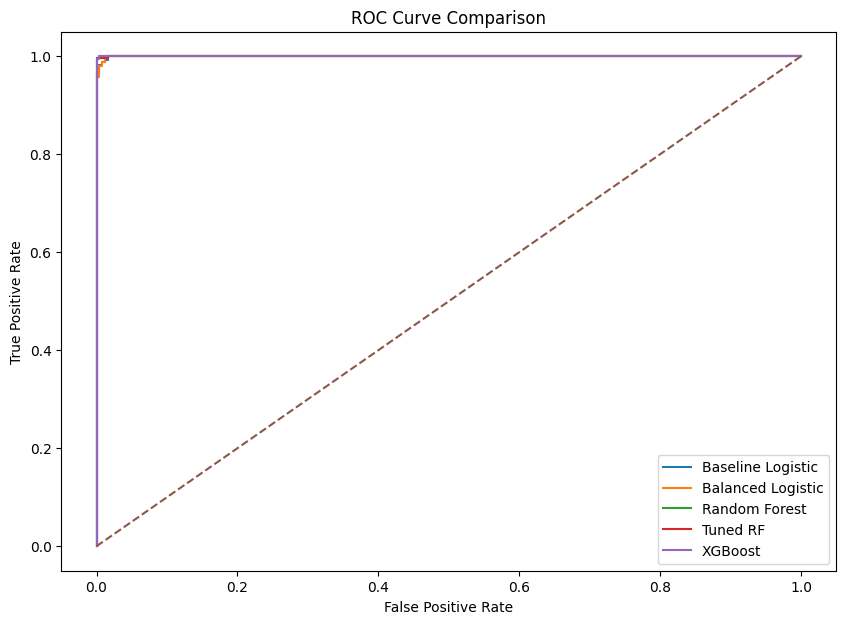

In [39]:
models_probs = {
    "Baseline Logistic": y_prob_base,
    "Balanced Logistic": y_prob_bal,
    "Random Forest": y_prob_rf,
    "Tuned RF": y_prob_best_rf,
    "XGBoost": y_prob_xgb
}

plt.figure(figsize=(10,7))

for model_name, probs in models_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=model_name)

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

# Threshold Tuning

#### Threshold tuning

In [40]:
custom_threshold = 0.35
y_pred_threshold = (y_prob_best_rf >= custom_threshold).astype(int)

print("Threshold Tuned Accuracy:", accuracy_score(y_test, y_pred_threshold))
print("Threshold Tuned Precision:", precision_score(y_test, y_pred_threshold))
print("Threshold Tuned Recall:", recall_score(y_test, y_pred_threshold))
print("Threshold Tuned F1 Score:", f1_score(y_test, y_pred_threshold))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_threshold))


Threshold Tuned Accuracy: 0.9916666666666667
Threshold Tuned Precision: 0.9861111111111112
Threshold Tuned Recall: 1.0
Threshold Tuned F1 Score: 0.993006993006993

Confusion Matrix:
 [[240   5]
 [  0 355]]


# Model Explainability using SHAP

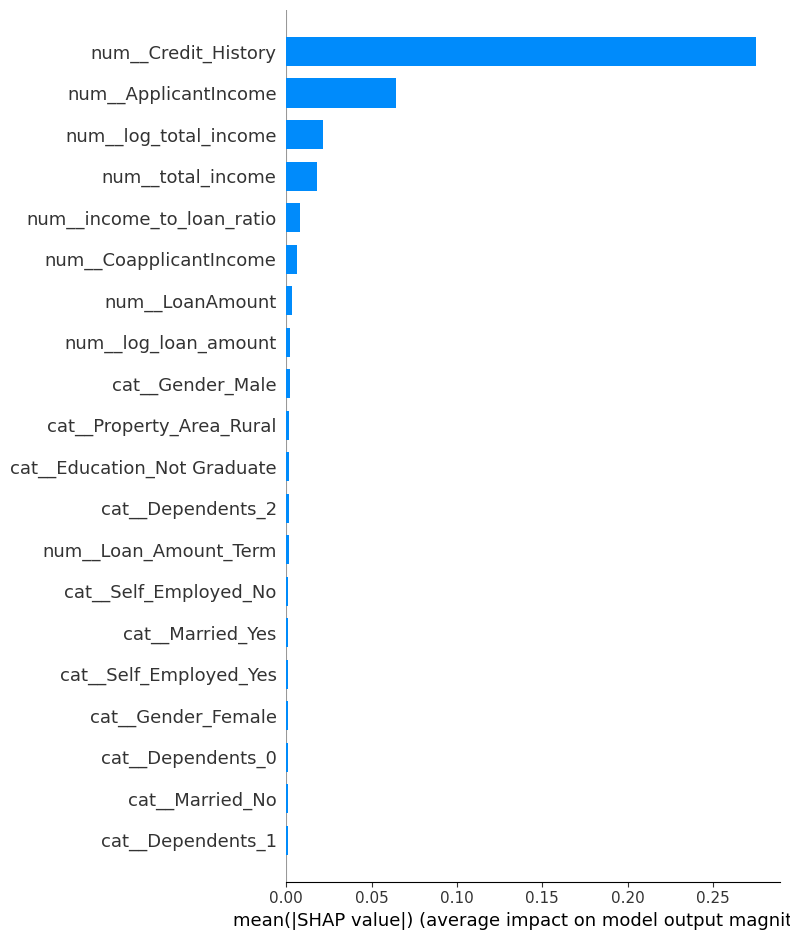

In [41]:
# If SHAP is not installed, run this once in a separate cell:
# !pip install shap

import shap
import numpy as np

# Use the final tuned Random Forest pipeline
final_model = best_rf_model

# Extract fitted preprocessor and Random Forest model from pipeline
preprocessor_fitted = final_model.named_steps["preprocessor"]
rf_final_model = final_model.named_steps["model"]

# Transform data exactly like the model sees it
X_train_processed = preprocessor_fitted.transform(X_train)
X_test_processed = preprocessor_fitted.transform(X_test)

# Get final feature names after one-hot encoding
feature_names = preprocessor_fitted.get_feature_names_out()

# Convert sparse matrix to dense array if required
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Use small sample to make SHAP faster
X_test_sample = X_test_processed[:100]

# Create SHAP explainer for Random Forest
explainer = shap.TreeExplainer(rf_final_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_sample)

# For binary classification, select class 1 explanation
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
elif len(np.array(shap_values).shape) == 3:
    shap_values_to_plot = shap_values[:, :, 1]
else:
    shap_values_to_plot = shap_values

# SHAP summary plot
shap.summary_plot(
    shap_values_to_plot,
    X_test_sample,
    feature_names=feature_names,
    plot_type="bar"
)


### SHAP Interpretation

SHAP explains how each feature contributes to the model prediction. In this project, it helps identify which factors are most responsible for loan approval or rejection decisions.

This improves model transparency and makes the project closer to a real-world financial risk decision system.


In [42]:
# Explain one sample prediction using SHAP values

sample_index = 0
sample_prediction = final_model.predict(X_test.iloc[[sample_index]])[0]
sample_probability = final_model.predict_proba(X_test.iloc[[sample_index]])[0, 1]

print("Sample Prediction:", sample_prediction)
print("Approval Probability:", round(sample_probability, 4))

# Top 10 features affecting this sample
sample_shap = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": shap_values_to_plot[sample_index]
}).sort_values(by="SHAP_Value", key=abs, ascending=False)

sample_shap.head(10)


Sample Prediction: 1
Approval Probability: 0.6673


,Feature,SHAP_Value
0,num__ApplicantIncome,0.342746
4,num__Credit_History,-0.172117
1,num__CoapplicantIncome,0.014677
7,num__log_total_income,-0.004851
3,num__Loan_Amount_Term,0.004410
5,num__total_income,-0.003592
12,cat__Married_Yes,-0.003039
23,cat__Property_Area_Urban,-0.002962
18,cat__Education_Not Graduate,-0.002646
21,cat__Property_Area_Rural,-0.002560


# Feature Importance

#### Extract feature importance from tuned RF

In [43]:
preprocessor_fitted = best_rf_model.named_steps["preprocessor"]
rf_final_model = best_rf_model.named_steps["model"]

num_features = preprocessor_fitted.transformers_[0][2]
cat_features = preprocessor_fitted.named_transformers_["cat"] \
    .named_steps["onehot"] \
    .get_feature_names_out(preprocessor_fitted.transformers_[1][2])

all_features = list(num_features) + list(cat_features)

feature_importance_df = pd.DataFrame({
    "Feature": all_features,
    "Importance": rf_final_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance_df.head(15)

,Feature,Importance
4,Credit_History,0.639691
0,ApplicantIncome,0.190600
7,log_total_income,0.044670
5,total_income,0.040924
6,income_to_loan_ratio,0.023585
1,CoapplicantIncome,0.022618
8,log_loan_amount,0.010871
2,LoanAmount,0.010660
3,Loan_Amount_Term,0.002320
15,Dependents_2,0.001467


#### Plot feature importance

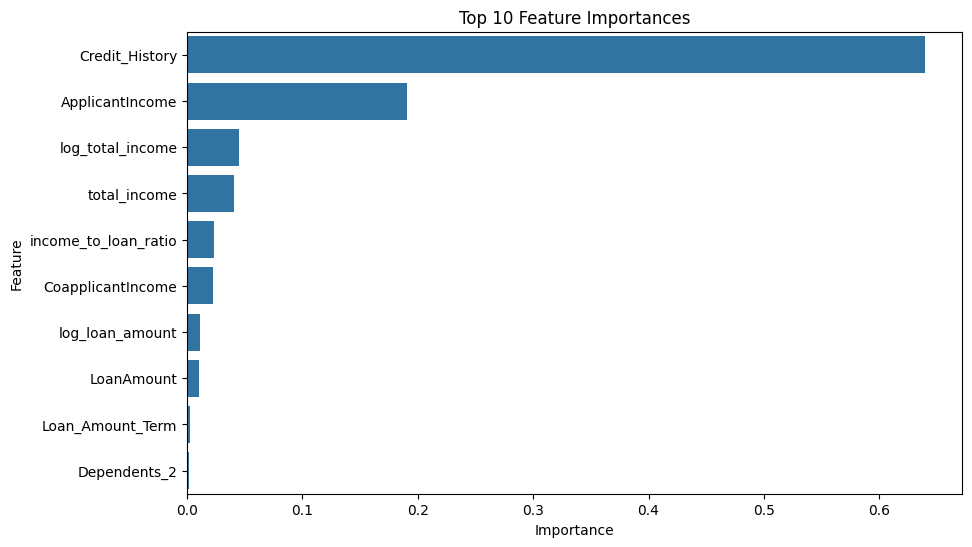

In [44]:
top_features = feature_importance_df.head(10)

plt.figure(figsize=(10,6))
sns.barplot(x="Importance", y="Feature", data=top_features)
plt.title("Top 10 Feature Importances")
plt.show()

# Save Final Best Model

In [45]:
joblib.dump(best_rf_model, "credit_risk_model.pkl")
print("Best Random Forest model saved successfully")

Best Random Forest model saved successfully


# Load Model Check

In [46]:
loaded_model = joblib.load("credit_risk_model.pkl")

sample_preds = loaded_model.predict(X_test.iloc[:5])
sample_probs = loaded_model.predict_proba(X_test.iloc[:5])[:, 1]

print("Sample Predictions:", sample_preds)
print("Sample Probabilities:", sample_probs)

Sample Predictions: [1 0 0 1 1]
Sample Probabilities: [0.66726186 0.24978449 0.1616264  0.78049951 0.97816353]


# Final Conclusion 

In [47]:
final_accuracy = accuracy_score(y_test, y_pred_best_rf)
final_roc_auc = roc_auc_score(y_test, y_prob_best_rf)

print("Project Completed Successfully")
print(f"Final selected model: Tuned Random Forest")
print(f"Final Accuracy: {final_accuracy:.4f}")
print(f"Final ROC-AUC: {final_roc_auc:.4f}")
print("Reason: Selected based on strong ROC-AUC, balanced performance, and business interpretability.")


Project Completed Successfully
Final selected model: Tuned Random Forest
Final Accuracy: 0.9967
Final ROC-AUC: 1.0000
Reason: Selected based on strong ROC-AUC, balanced performance, and business interpretability.
